In [1]:
import esm4ppe
from dask.diagnostics import ProgressBar
import matplotlib.pyplot as plt
import numpy as np

In [2]:
es = esm4ppe.esm4ppeObj('intpp','monthly').verify('ppp',dim=['member'])

Opening static... static opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening skill metric... skill metric opened.


### Calculate nino34 at initialization date

In [3]:
control = esm4ppe.open_controlzarr('ocean','monthly')
control = control.groupby('time.year').mean().rename({'year':'time'})
static = es.static

In [4]:
def calc_nino34(tos,area):
    box_dict = {'xh':slice(-170,-120),'yh':slice(-5,5)}
    tos_box = tos.sel(**box_dict).weighted(area).mean(['xh','yh'])
    return (tos_box - tos_box.mean('time'))/tos_box.std('time')

def calc_sosalinity(sos,area):
    box_dict = {'yh':slice(-90,-55)}
    sos_box = sos.sel(**box_dict).weighted(area).mean(['xh','yh'])
    return sos_box

In [5]:
nino34 = calc_nino34(control['tos'],static['areacello'])
nino34_init = nino34.sel(time=np.unique(es.vs['init'].dt.year))
nino34_init

<xarray.DataArray 'tos' (time: 10)>
dask.array<getitem, shape=(10,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) int64 123 161 185 208 230 269 300 326 359 381

In [6]:
# function to select specific month from array
def is_month(month,targetmonth):
    return month == targetmonth

targetmonth = 4
vs = es.vs.sel(init=is_month(es.vs['init.month'],targetmonth))
# assign nino index as coordinate
da_nino = vs['intpp'].assign_coords({'init':nino34_init.values})
# capture any rogue values of ppp
da_nino = da_nino.where(da_nino>0,0)
# specify nino bins
bins = np.arange(-2,2.1,1)
bins_c = 0.5*(bins[1:]+bins[:-1])
# group by nino value and average
da_ninobins_mean = da_nino.groupby_bins('init',bins,labels=bins_c).mean()

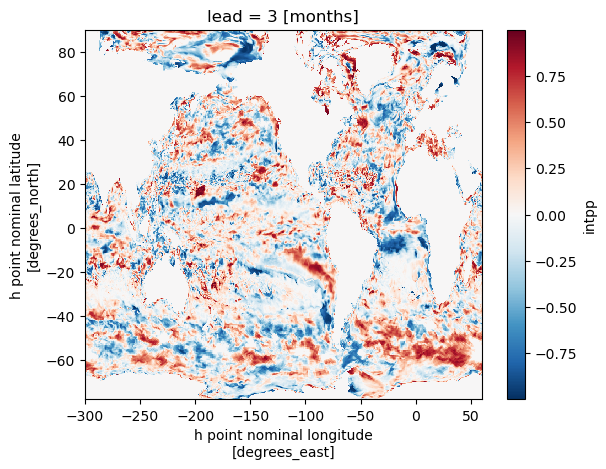

In [7]:
n34 = 1.5
lead = 3
(
    da_ninobins_mean.sel(init_bins=n34,lead=lead,method='nearest')
    -
    da_ninobins_mean.sel(init_bins=-1*n34,lead=lead,method='nearest')
).plot()

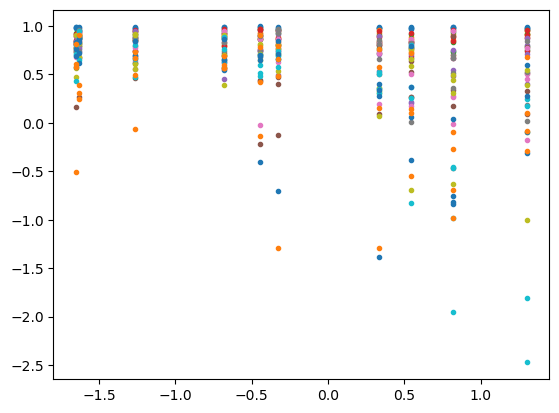

In [113]:
xh,yh = -150,0
fig,ax = plt.subplots()
for lead in np.arange(1,13):
    rho = vs['intpp'].sel(lead=lead,xh=xh,yh=yh,method='nearest')
    ax.plot(nino34_init,rho,marker='.',linestyle=' ')

In [77]:
vs_nino = vs.assign_coords({'init':nino34_init.values})

In [80]:
vs_nino.groupby_bins('init',np.arange(-2,2.1,0.1)).mean()

<xarray.Dataset>
Dimensions:    (lead: 120, xh: 720, yh: 576, init_bins: 40)
Coordinates:
  * lead       (lead) int64 1 2 3 4 5 6 7 8 ... 113 114 115 116 117 118 119 120
  * xh         (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh         (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
  * init_bins  (init_bins) object (-2.0, -1.9] (-1.9, -1.8] ... (1.9, 2.0]
Data variables:
    intpp      (init_bins, lead, yh, xh) float32 nan nan nan nan ... nan nan nan

### Regional mean

In [108]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',dim=['member'])
da_nino = ds['intpp'].sel(region='southern').assign_coords({'init':nino34_init.values})
da_nino = da_nino.where(da_nino>0,0)
da_ninobins = da_nino.groupby_bins('init',np.arange(-2,2.1,0.5))

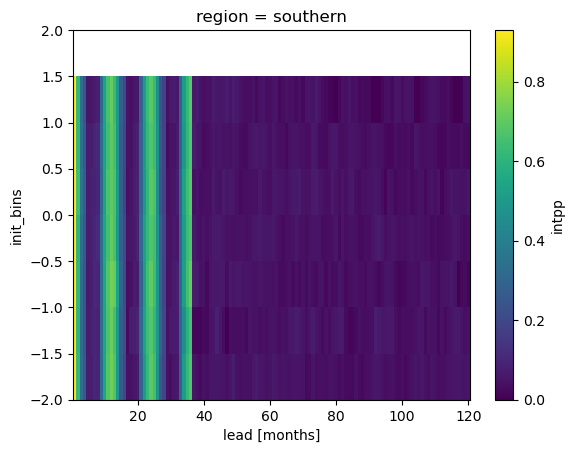

In [109]:
da_ninobins.mean().plot()

In [104]:
da_nino['intpp'].groupby_bins('init',np.arange(-2,2.1,0.5)).mean()

<xarray.DataArray 'intpp' (init_bins: 8, lead: 120)>
dask.array<where, shape=(8, 120), dtype=float64, chunksize=(2, 120), chunktype=numpy.ndarray>
Coordinates:
  * lead       (lead) int64 1 2 3 4 5 6 7 8 ... 113 114 115 116 117 118 119 120
  * init_bins  (init_bins) object (-2.0, -1.5] (-1.5, -1.0] ... (1.5, 2.0]
    region     <U20 'pacific_T'

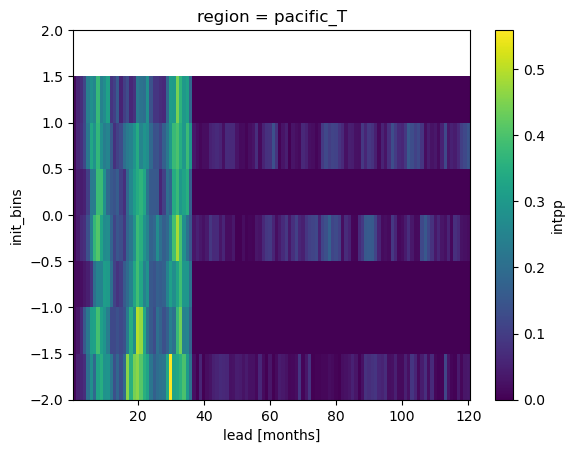

In [103]:
da_nino['intpp'].groupby_bins('init',np.arange(-2,2.1,0.5)).std().plot()